# Evaluación robusta y ajustes del modelo

Este notebook hace cuatro cosas: audita la procedencia/etiqueta del CSV; compara selección de modelos e hiperparámetros con validación cruzada anidada; ajusta dos umbrales de decisión con predicciones internas; y evalúa calibración sigmoide en folds externos. La unidad positiva se trata como `target=1` según la ficha del proveedor Kaggle. No se asume que ello equivalga a una etiqueta clínica independientemente validada.

La evaluación anidada usa los 302 registros distintos, cinco folds externos repetidos tres veces y tres folds internos. No hay una cohorte independiente/local en el repositorio, por lo que este ejercicio no constituye validación externa ni clínica.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/raw/heart.csv').exists():
    ROOT = ROOT.parent
if not (ROOT / 'data/raw/heart.csv').exists():
    raise FileNotFoundError('No se localizó data/raw/heart.csv')
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / 'outputs/figures'
TABLES = ROOT / 'outputs/tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(ROOT / 'data/raw/heart.csv')
print('Filas originales:', len(data), '| filas únicas:', len(data.drop_duplicates()))

Filas originales: 1025 | filas únicas: 302


## 1. Auditoría de la fuente y `target`

La comprobación consulta la API pública de Kaggle y compara el CSV descargado con el archivo local. El resultado puede confirmarse en la tabla guardada. La descripción de Kaggle dice `0 = no disease`, `1 = disease`; es una definición del proveedor, no una comprobación contra historias clínicas. Las diferencias de dominio observadas siguen registradas.

In [2]:
from src.source_audit import audit_local_source

audit = audit_local_source(ROOT / 'data/raw/heart.csv', verify_online=True)
audit.to_csv(TABLES / 'auditoria_fuente_target.csv', index=False)
display(audit)

,elemento,valor,interpretacion
0,archivo_local,C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear...,Fuente utilizada por el proyecto.
1,sha256_local,ddb2996b2f4db2e00aad13f4518200179ff69f79093838...,Huella del archivo auditado.
2,filas_locales,1025,Número de filas antes de deduplicar.
3,duplicados_exactos,723,Copias exactas sobre las 14 columnas.
4,filas_unicas,302,Observaciones distintas tras deduplicación exa...
5,target_conteos_original,"{""0"": 499, ""1"": 526}",Conteos por código de etiqueta.
6,target_conteos_unicos,"{""0"": 138, ""1"": 164}",Conteos tras deduplicación exacta.
7,combinaciones_predictoras_con_etiquetas_confli...,0,Grupos de predictores idénticos con target dis...
8,fuente_publicada,johnsmith88/heart-disease-dataset,Dataset de Kaggle declarado por el proyecto.
9,version_kaggle_consultada,2,Versión devuelta por la API de Kaggle al ejecu...


## 2. Validación anidada, calibración y umbrales

En cada fold externo se selecciona familia e hiperparámetros por ROC-AUC en los folds internos. La calibración sigmoide se ajusta sólo con el entrenamiento exterior. Los umbrales que maximizan balanced accuracy y F1 para la clase codificada 1 se eligen a partir de predicciones calibradas fuera de fold en ese entrenamiento; después se puntúan en el fold exterior. Así, la evaluación exterior mide el procedimiento completo sin usar sus etiquetas para seleccionar parámetros ni umbrales.

Los umbrales representan dos objetivos estadísticos distintos; ninguno se declara clínicamente óptimo. La desviación entre repeticiones es descriptiva porque las repeticiones reutilizan observaciones.

In [3]:
from src.robust_model_evaluation import nested_model_assessment, plot_nested_assessment

assessment = nested_model_assessment(
    data,
    n_splits=5,
    n_repeats=3,
    inner_splits=3,
    random_state=42,
    output_dir=TABLES,
)
plot_nested_assessment(assessment, FIGURES)
print('Folds externos:', len(assessment['fold_metrics']))
display(assessment['selected_model_counts'])
display(assessment['summary'].round(4))

C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [22:22:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Folds externos: 15


,selected_model,outer_folds_selected
0,LogisticRegression,14
1,XGBClassifier,1


,metric,mean_of_repeat_means,sd_across_repeat_means
0,threshold_balanced_accuracy,0.5330,0.0088
1,threshold_f1,0.4163,0.0229
2,outer_roc_auc_raw,0.9112,0.0104
3,outer_roc_auc_calibrated,0.9112,0.0104
4,outer_brier_raw,0.1197,0.0058
5,outer_brier_calibrated,0.1169,0.0055
6,outer_logloss_raw,0.3914,0.0174
7,outer_logloss_calibrated,0.3745,0.0155
8,raw_threshold_0_5_accuracy,0.8354,0.0069
9,raw_threshold_0_5_balanced_accuracy,0.8327,0.0069


In [4]:
# Detalle interpretable: métricas medias por repetición, sin tratar los folds como muestras independientes.
cols = [
    'repeat', 'outer_roc_auc_raw', 'outer_roc_auc_calibrated',
    'outer_brier_raw', 'outer_brier_calibrated',
    'calibrated_threshold_0_5_balanced_accuracy',
    'calibrated_threshold_balanced_balanced_accuracy',
    'calibrated_threshold_f1_f1_class_1',
    'threshold_balanced_accuracy', 'threshold_f1',
]
cols = [c for c in cols if c in assessment['repeat_means'].columns]
display(assessment['repeat_means'][cols].round(4))

,repeat,outer_roc_auc_raw,outer_roc_auc_calibrated,outer_brier_raw,outer_brier_calibrated,calibrated_threshold_0_5_balanced_accuracy,calibrated_threshold_balanced_balanced_accuracy,calibrated_threshold_f1_f1_class_1,threshold_balanced_accuracy,threshold_f1
0,1,0.9212,0.9212,0.1156,0.1126,0.8414,0.8322,0.8668,0.5414,0.4097
1,2,0.9120,0.9120,0.1170,0.1150,0.8363,0.8305,0.8442,0.5337,0.3974
2,3,0.9004,0.9004,0.1264,0.1231,0.8320,0.8330,0.8431,0.5239,0.4417


## 3. Lectura de los resultados

El ROC-AUC evalúa ordenamiento; Brier y log-loss evalúan scores probabilísticos en conjunto. La calibración sigmoide sólo se conserva si mejora de forma consistente la calidad probabilística externa. El umbral 0,5 y los dos umbrales ajustados se comparan en folds externos; el ajuste puede mejorar una métrica de clasificación mientras empeora otra.

No se debe elegir un punto de operación para pacientes a partir de este dataset. Para validación externa se necesita una cohorte distinta, autorizada, con variables y desenlace documentados y sin solapamiento de registros.

nested_cv_roc_auc_repeticiones.png


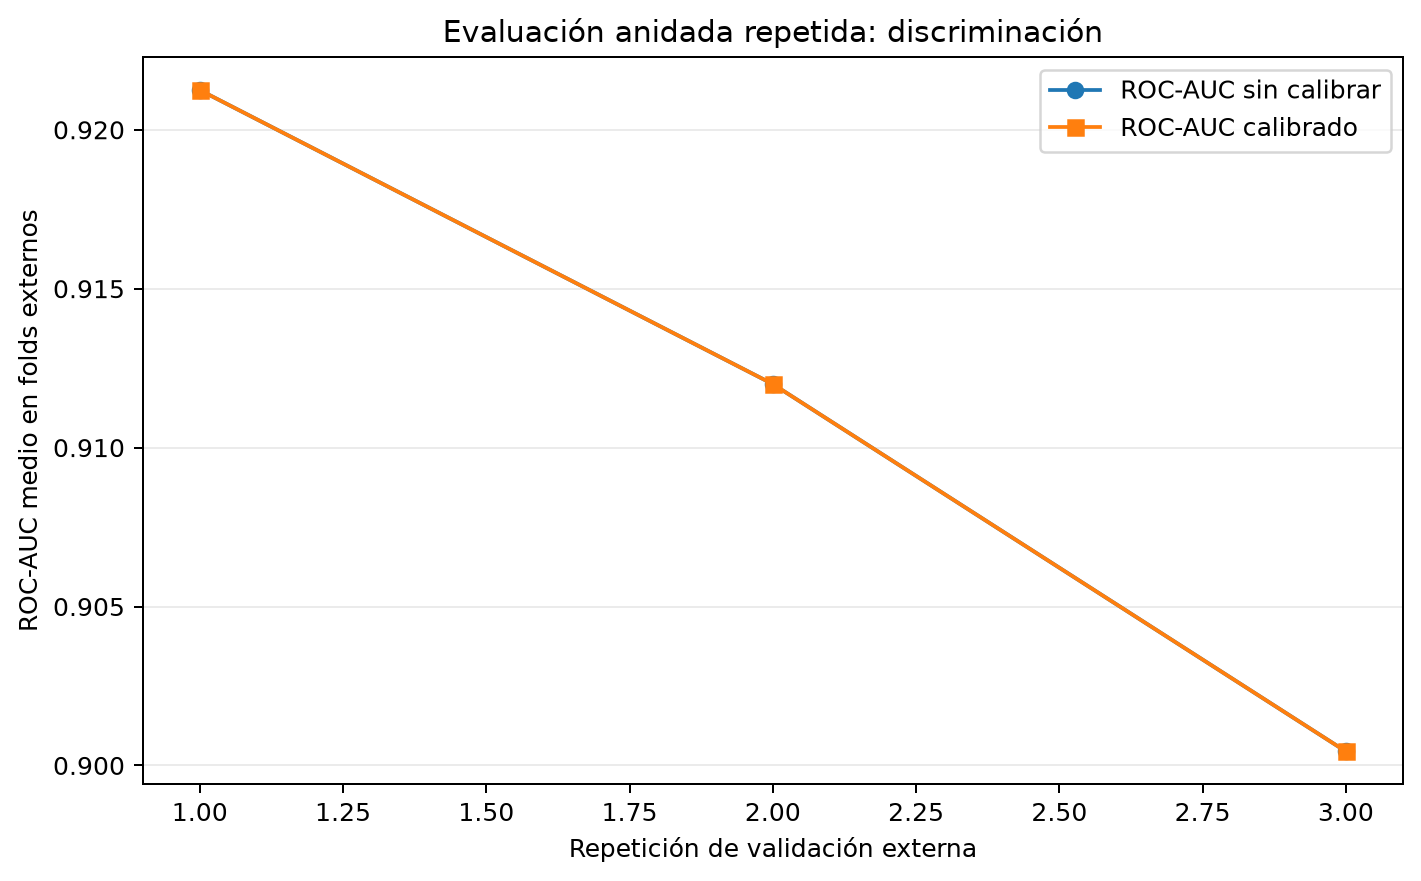

nested_cv_calibracion.png


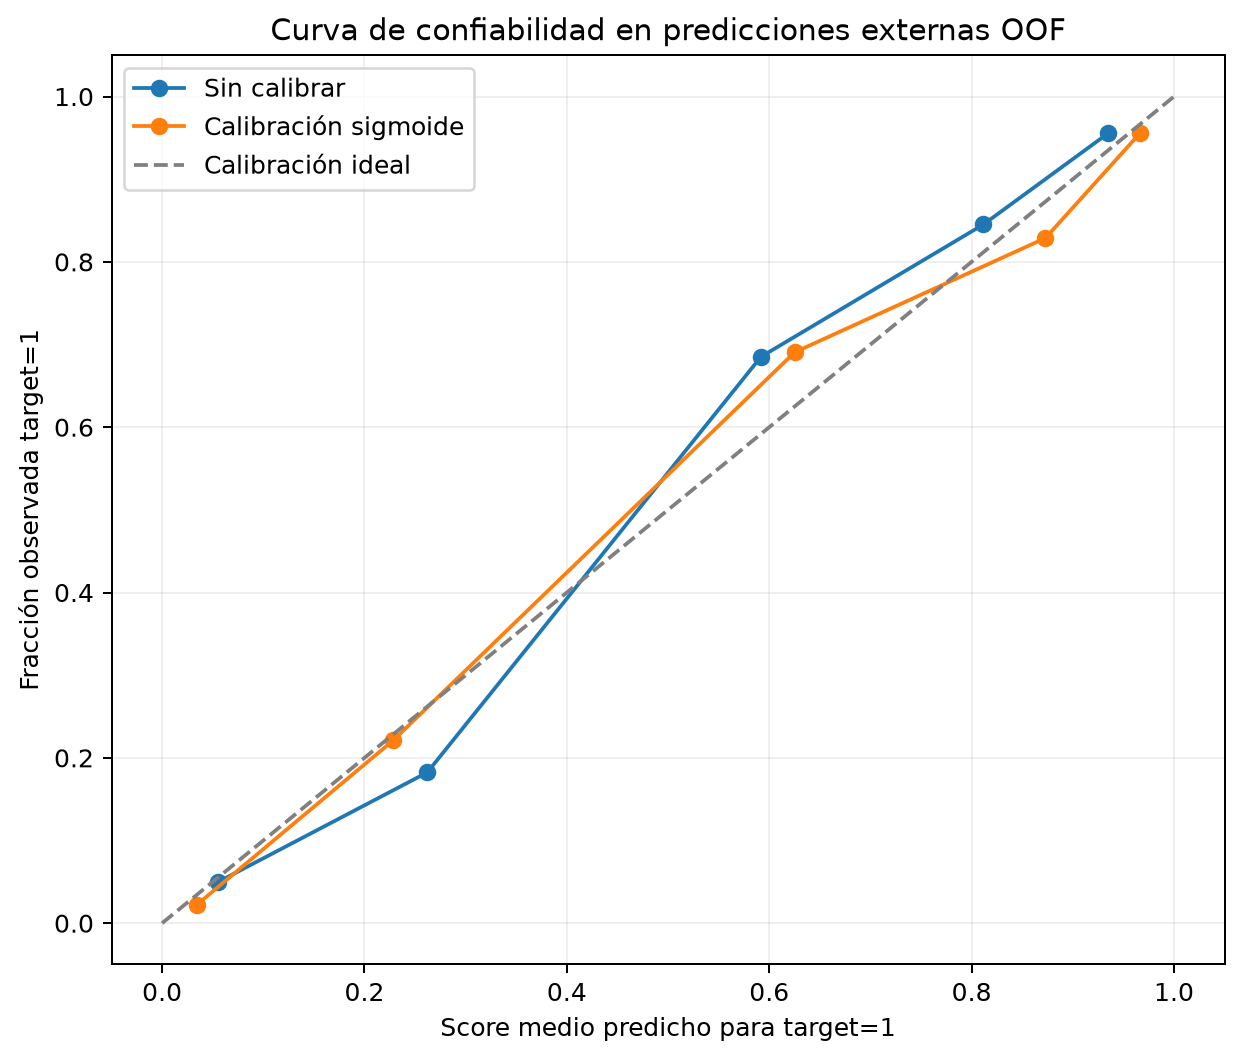

nested_cv_umbral.png


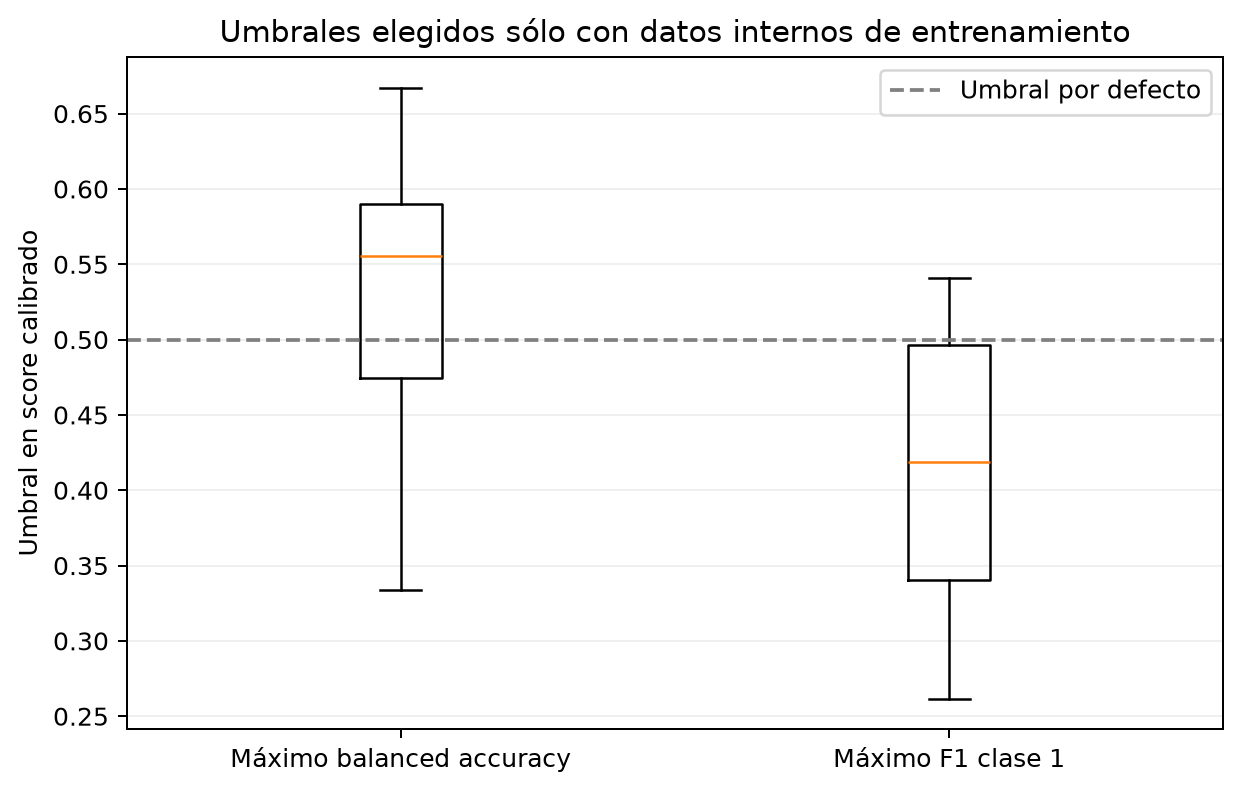

In [5]:
from IPython.display import Image, display
for name in ['nested_cv_roc_auc_repeticiones.png', 'nested_cv_calibracion.png', 'nested_cv_umbral.png']:
    print(name)
    display(Image(filename=str(FIGURES / name)))